# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [80]:
from IPython.display import display, Markdown

task1_answer = """
### Task 1.1 – Defining the Search Problem

**1. Initial State (Trạng thái ban đầu)**

Bàn cờ Mean Connect 4 ban đầu có kích thước 6 × 7,
gồm 42 ô trống. Mỗi ô được biểu diễn bằng:
- `0`: Ô trống
- `1`: Quân của người chơi MAX
- `-1`: Quân của người chơi MIN

Trạng thái trò chơi cần xác định cả bàn cờ và người đến lượt.

**2. Actions (Tập hành động)**

Người chơi có hai loại hành động:

- **Drop:** Thả một quân mới vào cột chưa đầy.
  Quân sẽ rơi xuống ô trống thấp nhất.
- **Move:** Lấy một quân của đối thủ ở hàng dưới cùng
  và thả quân đó vào một cột hợp lệ.
  Các quân phía trên vị trí vừa lấy sẽ rơi xuống một hàng.

**3. Transition Model (Mô hình chuyển trạng thái)**

Hàm `result(s, a)` tạo trạng thái mới sau khi thực hiện hành động.

- Với Drop: đặt quân của người chơi vào cột đã chọn.
- Với Move: lấy quân đáy của đối thủ, cho các quân phía trên
  rơi xuống, sau đó thả quân vừa lấy vào cột đích.
- Sau hành động, chuyển lượt cho người chơi còn lại.

**4. Terminal Test (Kiểm tra trạng thái kết thúc)**

Trò chơi kết thúc khi một người chơi tạo được bốn quân
liên tiếp theo hàng ngang, hàng dọc hoặc đường chéo.

Nếu không còn nước đi hợp lệ và không có người thắng,
trò chơi kết thúc với kết quả hòa.

**5. Utility Function (Hàm lợi ích)**

Hàm utility đánh giá trạng thái kết thúc theo góc nhìn MAX:

- `+1`: MAX thắng.
- `-1`: MIN thắng.
- `0`: Hòa.

Các trạng thái chưa kết thúc chưa có giá trị utility cuối cùng.
"""

display(Markdown(task1_answer))


### Task 1.1 – Defining the Search Problem

**1. Initial State (Trạng thái ban đầu)**

Bàn cờ Mean Connect 4 ban đầu có kích thước 6 × 7,
gồm 42 ô trống. Mỗi ô được biểu diễn bằng:
- `0`: Ô trống
- `1`: Quân của người chơi MAX
- `-1`: Quân của người chơi MIN

Trạng thái trò chơi cần xác định cả bàn cờ và người đến lượt.

**2. Actions (Tập hành động)**

Người chơi có hai loại hành động:

- **Drop:** Thả một quân mới vào cột chưa đầy.
  Quân sẽ rơi xuống ô trống thấp nhất.
- **Move:** Lấy một quân của đối thủ ở hàng dưới cùng
  và thả quân đó vào một cột hợp lệ.
  Các quân phía trên vị trí vừa lấy sẽ rơi xuống một hàng.

**3. Transition Model (Mô hình chuyển trạng thái)**

Hàm `result(s, a)` tạo trạng thái mới sau khi thực hiện hành động.

- Với Drop: đặt quân của người chơi vào cột đã chọn.
- Với Move: lấy quân đáy của đối thủ, cho các quân phía trên
  rơi xuống, sau đó thả quân vừa lấy vào cột đích.
- Sau hành động, chuyển lượt cho người chơi còn lại.

**4. Terminal Test (Kiểm tra trạng thái kết thúc)**

Trò chơi kết thúc khi một người chơi tạo được bốn quân
liên tiếp theo hàng ngang, hàng dọc hoặc đường chéo.

Nếu không còn nước đi hợp lệ và không có người thắng,
trò chơi kết thúc với kết quả hòa.

**5. Utility Function (Hàm lợi ích)**

Hàm utility đánh giá trạng thái kết thúc theo góc nhìn MAX:

- `+1`: MAX thắng.
- `-1`: MIN thắng.
- `0`: Hòa.

Các trạng thái chưa kết thúc chưa có giá trị utility cuối cùng.


How big is the state space? Give an estimate and explain it.

In [81]:
# Task 1.2 - Estimate the state space of Mean Connect 4

rows = 6
cols = 7

# Upper bound without game constraints
naive_states = 3 ** (rows * cols)

# Number of possible column configurations
# respecting gravity
column_states = sum(2 ** h for h in range(rows + 1))

# Upper bound respecting gravity
gravity_states = column_states ** cols

print("=== MEAN CONNECT 4: STATE SPACE ===")
print(f"Board size: {rows} x {cols}")
print(f"Total cells: {rows * cols}")
print(f"Naive upper bound: {naive_states:,}")
print(f"Possible configurations per column: {column_states}")
print(f"Gravity-based upper bound: {gravity_states:,}")

=== MEAN CONNECT 4: STATE SPACE ===
Board size: 6 x 7
Total cells: 42
Naive upper bound: 109,418,989,131,512,359,209
Possible configurations per column: 127
Gravity-based upper bound: 532,875,860,165,503


### Nhận xét – State Space của Mean Connect 4
Bàn cờ 6×7 có 42 ô, với giới hạn trên sơ bộ là \(3^{42}\) cấu hình. Tuy nhiên, số trạng thái thực tế có thể đạt được sẽ ít hơn do các ràng buộc về trọng lực và luật chơi.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [82]:
# Task 1.3 - Estimate the game tree of Mean Connect 4

rows = 6
cols = 7

# Standard Connect 4: at most 7 drop actions
standard_max_branching = cols

# Mean Connect 4:
# At most 7 drop actions
# At most 7 opponent bottom discs x 7 destination columns
mean_max_branching = cols + cols * cols

print("=== MEAN CONNECT 4: GAME TREE ===")
print("Maximum branching factor (standard):", standard_max_branching)
print("Upper bound branching factor (Mean):", mean_max_branching)

print("\nEstimated search tree size (upper bounds):")

for depth in [2, 4, 6, 8]:
    standard_nodes = sum(
        standard_max_branching ** i
        for i in range(depth + 1)
    )

    mean_nodes = sum(
        mean_max_branching ** i
        for i in range(depth + 1)
    )

    print(f"\nDepth = {depth}")
    print(f"Standard Connect 4: {standard_nodes:,} nodes")
    print(f"Mean Connect 4:     {mean_nodes:,} nodes")

=== MEAN CONNECT 4: GAME TREE ===
Maximum branching factor (standard): 7
Upper bound branching factor (Mean): 56

Estimated search tree size (upper bounds):

Depth = 2
Standard Connect 4: 57 nodes
Mean Connect 4:     3,193 nodes

Depth = 4
Standard Connect 4: 2,801 nodes
Mean Connect 4:     10,013,305 nodes

Depth = 6
Standard Connect 4: 137,257 nodes
Mean Connect 4:     31,401,724,537 nodes

Depth = 8
Standard Connect 4: 6,725,601 nodes
Mean Connect 4:     98,475,808,148,089 nodes


### Nhận xét – Game Tree của Mean Connect 4

Mean Connect 4 có số nhánh tìm kiếm lớn hơn Connect 4 thông thường do người chơi có thể thả quân hoặc di chuyển quân đáy của đối thủ, làm tăng độ phức tạp của cây trò chơi.


## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [83]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

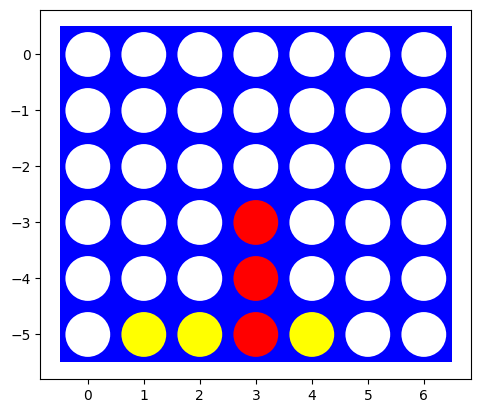

In [84]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

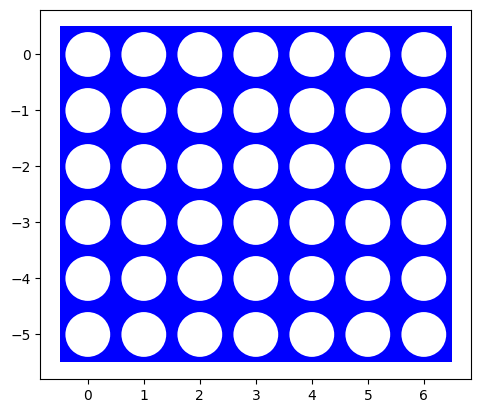

In [85]:
initial_board = empty_board((6, 7))
visualize(initial_board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [86]:
import numpy as np

# Action formats:
# ("drop", column)
# ("move", source_column, target_column)

def actions(board, player=1):
    board = np.asarray(board)
    rows, cols = board.shape
    legal = []

    # 1. Drop a new disc
    for col in range(cols):
        if board[0, col] == 0:
            legal.append(("drop", col))
    
    # 2. Move an opponent's bottom disc
    for src in range(cols):
        if board[rows - 1, src] == -player:
            for dst in range(cols):
                if dst == src or board[0, dst] == 0:
                    legal.append(("move", src, dst))

    return legal


def result(board, action, player=1):
    board = np.asarray(board)
    new_board = board.copy()

    if action not in actions(board, player):
        raise ValueError(f"Invalid action: {action}")

    rows, cols = board.shape

    if action[0] == "drop":
        col = action[1]

        # Place the disc in the lowest empty cell
        for row in range(rows - 1, -1, -1):
            if new_board[row, col] == 0:
                new_board[row, col] = player
                break

    elif action[0] == "move":
        src, dst = action[1], action[2]

        # Take the opponent's bottom disc
        disc = new_board[rows - 1, src]

        # Shift all discs above it down
        new_board[1:, src] = new_board[:-1, src]
        new_board[0, src] = 0

        # Drop the removed disc into destination column
        for row in range(rows - 1, -1, -1):
            if new_board[row, dst] == 0:
                new_board[row, dst] = disc
                break

    return new_board


def check_winner(board, connect=4):
    board = np.asarray(board)
    rows, cols = board.shape
    winners = set()

    directions = [
        (0, 1),    # Horizontal
        (1, 0),    # Vertical
        (1, 1),    # Diagonal down-right
        (1, -1)    # Diagonal down-left
    ]

    for row in range(rows):
        for col in range(cols):
            player = board[row, col]

            if player == 0:
                continue

            for dr, dc in directions:
                end_row = row + (connect - 1) * dr
                end_col = col + (connect - 1) * dc

                if not (0 <= end_row < rows and
                        0 <= end_col < cols):
                    continue

                if all(
                    board[row + k * dr, col + k * dc] == player
                    for k in range(connect)
                ):
                    winners.add(int(player))

    return winners


def terminal(board, player=1, connect=4):
    # A player has four connected discs
    if check_winner(board, connect):
        return True

    # No legal actions for the player to move
    if len(actions(board, player)) == 0:
        return True

    return False


def utility(board, player=1, connect=4):
    winners = check_winner(board, connect)

    if not winners:
        if terminal(board, player, connect):
            return 0
        return None

    # Both players have winning lines:
    # treated as a draw under this implementation
    if len(winners) == 2:
        return 0

    winner = next(iter(winners))

    # Utility from MAX's perspective
    return 1 if winner == 1 else -1


print("=== MEAN CONNECT 4 FUNCTIONS READY ===")
print("actions(), result(), terminal(), utility()")

=== MEAN CONNECT 4 FUNCTIONS READY ===
actions(), result(), terminal(), utility()


In [87]:
# Task 2 - Game Environment Tests

# TEST 1: Empty board
board = empty_board((6, 7))

assert len(actions(board, 1)) == 7
assert terminal(board, 1) is False
assert utility(board, 1) is None

print("TEST 1 - Empty board: PASSED")

# TEST 2: Drop action
board = result(board, ("drop", 3), -1)
board = result(board, ("drop", 3), 1)

assert board[5, 3] == -1
assert board[4, 3] == 1

print("TEST 2 - Drop action: PASSED")

# TEST 3: Move action
moved_board = result(board, ("move", 3, 4), 1)

assert moved_board[5, 3] == 1
assert moved_board[5, 4] == -1
assert moved_board[4, 3] == 0

print("TEST 3 - Move action: PASSED")


# TEST 4 - Same-column Move

board = np.array([
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [1, 0, 0, 0],
    [-1, 0, 0, 0]
])

action = ("move", 0, 0)

assert action in actions(board, 1)

new_board = result(board, action, 1)

assert new_board[3, 0] == 1
assert new_board[2, 0] == -1

print("TEST 4 - Same-column Move: PASSED")


# TEST 5 - Simultaneous Winners

board = np.array([
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [1, 1, 1, 1],
    [-1, -1, -1, -1]
])

assert check_winner(board) == {1, -1}
assert terminal(board, player=1) is True
assert utility(board, player=1) == 0

print("TEST 5 - Simultaneous Winners: PASSED")
print("Winners:", check_winner(board))
print("Utility:", utility(board, 1))

print("\n=== ALL GAME ENVIRONMENT TESTS PASSED ===")

TEST 1 - Empty board: PASSED
TEST 2 - Drop action: PASSED
TEST 3 - Move action: PASSED
TEST 4 - Same-column Move: PASSED
TEST 5 - Simultaneous Winners: PASSED
Winners: {1, -1}
Utility: 0

=== ALL GAME ENVIRONMENT TESTS PASSED ===


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

=== RANDOM AGENT TEST ===
Initial board:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

Number of legal actions: 7
Selected action: ('drop', 4)
Is action valid: True

Board after Random Agent moves:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0]]


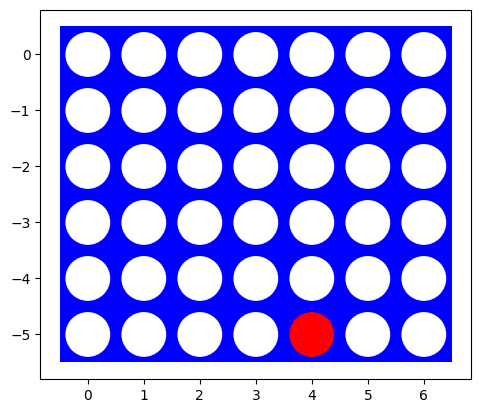

In [88]:
# Task 2 - Random Agent for Mean Connect 4

import numpy as np

def random_player(board, player=1):
    legal_actions = actions(board, player)

    if not legal_actions:
        return None

    # Randomly choose one legal action
    index = np.random.randint(len(legal_actions))
    return legal_actions[index]


# Test Random Agent
np.random.seed(1111)

board = empty_board((6, 7))

print("=== RANDOM AGENT TEST ===")
print("Initial board:")
print(board)

print("\nNumber of legal actions:", len(actions(board, 1)))

action = random_player(board, player=1)

print("Selected action:", action)
print("Is action valid:", action in actions(board, 1))

new_board = result(board, action, player=1)

print("\nBoard after Random Agent moves:")
print(new_board)

visualize(new_board)

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [89]:
# Task 2 - Random vs Random: 1000 games

import numpy as np
import time

def play_random_game(shape=(6, 7), max_moves=200):
    board = empty_board(shape)
    player = 1

    for turn in range(max_moves):
        if terminal(board, player):
            score = utility(board, player)
            return score, turn, False

        action = random_player(board, player)
        if action is None:
            return 0, turn, False

        board = result(board, action, player)
        player = -player

    # Reached the experiment's move limit
    if terminal(board, player):
        return utility(board, player), max_moves, False

    return None, max_moves, True


np.random.seed(1111)

N = 1000
max_moves = 200

wins_max = 0
wins_min = 0
draws = 0
limit_reached = 0
total_moves = 0

start = time.perf_counter()

for _ in range(N):
    score, moves, timeout = play_random_game(
        shape=(6, 7),
        max_moves=max_moves
    )

    total_moves += moves

    if timeout:
        limit_reached += 1
    elif score == 1:
        wins_max += 1
    elif score == -1:
        wins_min += 1
    else:
        draws += 1

elapsed = time.perf_counter() - start

print("=== MEAN CONNECT 4: RANDOM VS RANDOM ===")
print(f"Total games       : {N}")
print(f"MAX wins          : {wins_max}")
print(f"MIN wins          : {wins_min}")
print(f"Draws             : {draws}")
print(f"Move limit reached: {limit_reached}")
print(f"Total check       : {wins_max + wins_min + draws + limit_reached}")
print(f"Average moves     : {total_moves / N:.2f}")
print(f"Total time        : {elapsed:.3f} seconds")

=== MEAN CONNECT 4: RANDOM VS RANDOM ===
Total games       : 1000
MAX wins          : 760
MIN wins          : 236
Draws             : 4
Move limit reached: 0
Total check       : 1000
Average moves     : 24.86
Total time        : 0.916 seconds


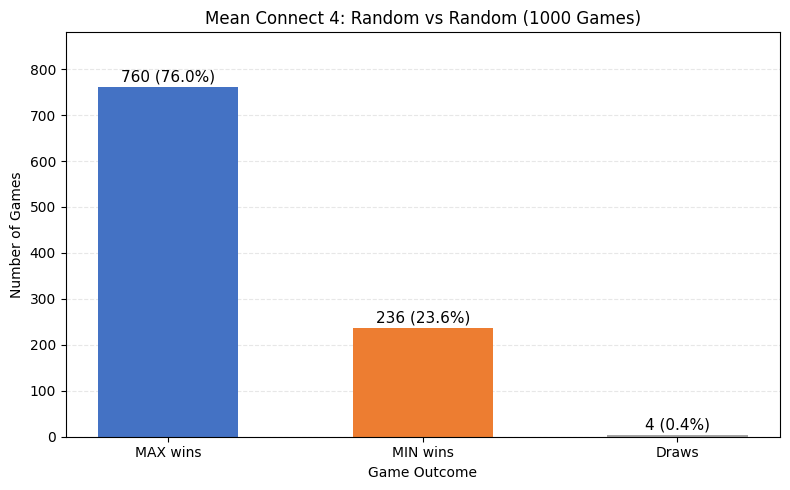

In [90]:
# Figure 3.2 - Random vs Random Results

import matplotlib.pyplot as plt

outcomes = ["MAX wins", "MIN wins", "Draws"]
counts = [760, 236, 4]
colors = ["#4472C4", "#ED7D31", "#A5A5A5"]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(outcomes, counts, color=colors, width=0.55)

for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 12,
        f"{count} ({count / 1000 * 100:.1f}%)",
        ha="center",
        fontsize=11
    )

ax.set_title("Mean Connect 4: Random vs Random (1000 Games)")
ax.set_xlabel("Game Outcome")
ax.set_ylabel("Number of Games")
ax.set_ylim(0, 880)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Nhận xét thực nghiệm – Random vs Random

Sau 1.000 ván đấu, MAX thắng 760 ván (76%), MIN thắng 236 ván (23,6%) và hòa 4 ván (0,4%). Số lượt trung bình là 24,86 lượt/ván.

## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [91]:
import numpy as np
import time

# Task 3 - Minimax with Alpha-Beta Pruning

def alpha_beta_search(board, player=1, max_nodes=100000):
    """
    Minimax with Alpha-Beta Pruning.

    player:
        1  = MAX
       -1  = MIN

    max_nodes:
        Maximum number of recursive search nodes.

    Repeated states on the current search path
    are treated as draws (experimental convention).
    """

    board = np.asarray(board)
    node_count = 0
    start = time.perf_counter()

    # Recursive Minimax + Alpha-Beta
    def search(state, turn, alpha, beta, path):
        nonlocal node_count

        node_count += 1

        if node_count > max_nodes:
            raise RuntimeError(
                "Search node limit reached. "
                "Try a smaller or near-terminal board."
            )

        # Check terminal state
        score = utility(state, turn)

        if score is not None:
            return score

        # Detect repeated states
        key = (state.tobytes(), turn)

        if key in path:
            return 0

        next_path = path | {key}
        legal = actions(state, turn)

        if turn == 1:
            # MAX tries to maximize utility
            best_value = -float("inf")

            for action in legal:
                child = result(state, action, turn)

                value = search(
                    child, -turn, alpha, beta, next_path
                )

                best_value = max(best_value, value)
                alpha = max(alpha, best_value)

                if alpha >= beta:
                    break

        else:
            # MIN tries to minimize utility
            best_value = float("inf")

            for action in legal:
                child = result(state, action, turn)

                value = search(
                    child, -turn, alpha, beta, next_path
                )

                best_value = min(best_value, value)
                beta = min(beta, best_value)

                if alpha >= beta:
                    break

        return best_value

    # Get legal actions
    legal = actions(board, player)

    if terminal(board, player) or not legal:
        elapsed = time.perf_counter() - start
        return None, utility(board, player), 0, elapsed

    # Check for an immediate winning move
    for action in legal:
        next_board = result(board, action, player)

        if utility(next_board, -player) == player:
            elapsed = time.perf_counter() - start
            return action, player, 0, elapsed

    # Search all possible root actions
    best_action = None
    best_value = (
        -float("inf") if player == 1
        else float("inf")
    )

    alpha = -float("inf")
    beta = float("inf")

    for action in legal:
        child = result(board, action, player)

        value = search(
            child,
            -player,
            alpha,
            beta,
            {(board.tobytes(), player)}
        )

        if player == 1:
            if value > best_value:
                best_value = value
                best_action = action

            alpha = max(alpha, best_value)

        else:
            if value < best_value:
                best_value = value
                best_action = action

            beta = min(beta, best_value)

    elapsed = time.perf_counter() - start

    return best_action, best_value, node_count, elapsed


def alpha_beta_player(board, player=1):
    action, value, nodes, elapsed = alpha_beta_search(
        board,
        player=player
    )
    return action


print("=== ALPHA-BETA AGENT READY ===")
print("Functions: alpha_beta_search(), alpha_beta_player()")


=== ALPHA-BETA AGENT READY ===
Functions: alpha_beta_search(), alpha_beta_player()


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [92]:
# Task 3 - Five Manual Tests for Alpha-Beta

import numpy as np

board_test3 = np.array([
    [0, 0],
    [1, -1]
])

test_boards_task3 = [
    (
        "TEST 1 - MAX immediate win",
        np.array([
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [1, 1, 1, 0]
        ]),
        1
    ),
    (
        "TEST 2 - MIN immediate win",
        np.array([
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [-1, -1, -1, 0]
        ]),
        -1
    ),
    (
        "TEST 3 - Small board",
        board_test3,
        1
    ),
    (
        "TEST 4 - MAX vertical immediate win",
        np.array([
            [0, 0, 0, 0],
            [1, 0, 0, 0],
            [1, 0, 0, 0],
            [1, 0, 0, 0]
        ]),
        1
    ),
    (
        "TEST 5 - Already terminal",
        np.array([
            [0, 0, 0, 1],
            [0, 0, 1, -1],
            [0, 1, -1, -1],
            [1, -1, -1, -1]
        ]),
        -1
    )
]

print("=== TASK 3: ALPHA-BETA MANUAL TESTS ===")


for name, board, player in test_boards_task3:

    print(f"\n{name}")

    try:
        action, value, nodes, elapsed = alpha_beta_search(
            board,
            player=player,
            max_nodes=100000
        )

        print("Best action:", action)
        print("Minimax value:", value)
        print("Nodes searched:", nodes)
        print(f"Time: {elapsed:.6f}s")

        if action is not None:
            next_board = result(board, action, player)
            print("Winner after move:", check_winner(next_board))
        else:
            print("Terminal board:", terminal(board, player))

    except RuntimeError as e:
        print("Status: Node limit reached")
        print("Reason:", e)
        print("Best action: Not determined")
        print("Minimax value: Not determined")

=== TASK 3: ALPHA-BETA MANUAL TESTS ===

TEST 1 - MAX immediate win
Best action: ('drop', 3)
Minimax value: 1
Nodes searched: 0
Time: 0.000108s
Winner after move: {1}

TEST 2 - MIN immediate win
Best action: ('drop', 3)
Minimax value: -1
Nodes searched: 0
Time: 0.000081s
Winner after move: {-1}

TEST 3 - Small board
Best action: ('drop', 0)
Minimax value: 0
Nodes searched: 47
Time: 0.000616s
Winner after move: set()

TEST 4 - MAX vertical immediate win
Best action: ('drop', 0)
Minimax value: 1
Nodes searched: 0
Time: 0.000027s
Winner after move: {1}

TEST 5 - Already terminal
Best action: None
Minimax value: 1
Nodes searched: 0
Time: 0.000014s
Terminal board: True


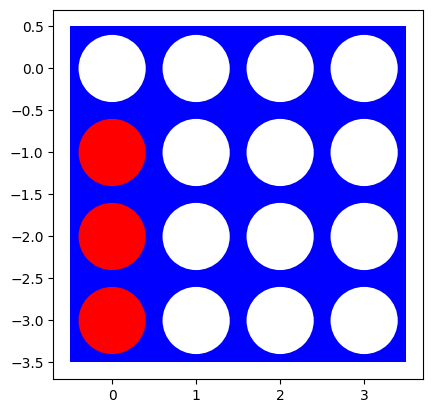

In [93]:
# Figure 3.3 - MAX Vertical Winning Position

board_fig33 = np.array([
    [0, 0, 0, 0],
    [1, 0, 0, 0],
    [1, 0, 0, 0],
    [1, 0, 0, 0]
])

visualize(board_fig33)

**Nhận xét:** Alpha-Beta nhận diện đúng các nước thắng tức thời theo chiều ngang và chiều dọc, lựa chọn được nước đi hợp lệ trên bàn nhỏ và xử lý đúng trạng thái kết thúc. Các trường hợp thắng tức thời được giải quyết bằng bước kiểm tra chiến thuật trước khi tìm kiếm đệ quy.

In [94]:
# Task 3 - Compare Minimax and Alpha-Beta

import time

def minimax_search(board, player=1, max_nodes=10000):
    node_count = 0
    start = time.perf_counter()

    def search(state, turn, path):
        nonlocal node_count

        node_count += 1

        if node_count > max_nodes:
            raise RuntimeError("Minimax node limit reached")

        score = utility(state, turn)
        if score is not None:
            return score

        key = (state.tobytes(), turn)

        if key in path:
            return 0

        next_path = path | {key}
        values = []

        for action in actions(state, turn):
            child = result(state, action, turn)
            values.append(
                search(child, -turn, next_path)
            )

        if turn == 1:
            return max(values)
        return min(values)

    if terminal(board, player):
        return None, utility(board, player), 0, 0.0

    best_action = None
    best_value = -float("inf") if player == 1 else float("inf")

    for action in actions(board, player):
        child = result(board, action, player)

        value = search(
            child,
            -player,
            {(board.tobytes(), player)}
        )

        if (
            (player == 1 and value > best_value)
            or (player == -1 and value < best_value)
        ):
            best_value = value
            best_action = action

    elapsed = time.perf_counter() - start

    return best_action, best_value, node_count, elapsed


# Use the same board for both algorithms
test_board = board_test3.copy()

print("=== MINIMAX VS ALPHA-BETA ===")

mm_action, mm_value, mm_nodes, mm_time = minimax_search(
    test_board, player=1
)

ab_action, ab_value, ab_nodes, ab_time = alpha_beta_search(
    test_board, player=1
)

print("\nMinimax:")
print("Best action:", mm_action)
print("Value:", mm_value)
print("Nodes:", mm_nodes)
print(f"Time: {mm_time:.6f} seconds")

print("\nAlpha-Beta:")
print("Best action:", ab_action)
print("Value:", ab_value)
print("Nodes:", ab_nodes)
print(f"Time: {ab_time:.6f} seconds")

print("\nSame Minimax value:", mm_value == ab_value)
print("Same action:", mm_action == ab_action)
print("Nodes saved:", mm_nodes - ab_nodes)

=== MINIMAX VS ALPHA-BETA ===

Minimax:
Best action: ('drop', 0)
Value: 0
Nodes: 4402
Time: 0.054452 seconds

Alpha-Beta:
Best action: ('drop', 0)
Value: 0
Nodes: 47
Time: 0.000605 seconds

Same Minimax value: True
Same action: True
Nodes saved: 4355


### Nhận xét – So sánh Minimax và Alpha-Beta Pruning

Hai thuật toán chọn cùng nước đi với giá trị Minimax bằng 0. Alpha-Beta giảm số nút tìm kiếm từ 4.402 xuống 47, tương đương khoảng 98,93%.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [95]:
# Task 3 - Execution time as board width increases

import numpy as np
import time

max_nodes = 2000
experiment_results = []

print("=== ALPHA-BETA: EXECUTION TIME ===")

for cols in [4, 5, 6, 7]:

    # Keep board height fixed at 4 rows
    board = empty_board((4, cols))

    # Create a non-terminal test position
    # by dropping alternating discs
    current_player = 1

    for col in range(cols):
        board = result(
            board, ("drop", col), current_player
        )
        current_player = -current_player

    print(f"\nBoard size: 4 x {cols}")
    print("Player to move:", current_player)

    start = time.perf_counter()

    try:
        action, value, nodes, _ = alpha_beta_search(
            board,
            player=current_player,
            max_nodes=max_nodes
        )

        elapsed = time.perf_counter() - start
        status = "Completed"

    except RuntimeError as e:
        elapsed = time.perf_counter() - start
        action = None
        value = None
        nodes = None
        status = "Node limit reached"

    experiment_results.append({
        "board": f"4x{cols}",
        "status": status,
        "action": action,
        "value": value,
        "nodes": nodes,
        "time": elapsed
    })

    print("Status:", status)
    print("Best action:", action)
    print("Minimax value:", value)
    print("Nodes searched:", nodes if nodes is not None else "Not available")
    print(f"Time: {elapsed:.4f} seconds")


print("\n=== SUMMARY ===")

for r in experiment_results:
    print(
        f"{r['board']} | "
        f"{r['status']} | "
        f"{r['time']:.4f} seconds"
    )


=== ALPHA-BETA: EXECUTION TIME ===

Board size: 4 x 4
Player to move: 1


Status: Node limit reached
Best action: None
Minimax value: None
Nodes searched: Not available
Time: 0.0919 seconds

Board size: 4 x 5
Player to move: -1
Status: Node limit reached
Best action: None
Minimax value: None
Nodes searched: Not available
Time: 0.1023 seconds

Board size: 4 x 6
Player to move: 1
Status: Node limit reached
Best action: None
Minimax value: None
Nodes searched: Not available
Time: 0.1415 seconds

Board size: 4 x 7
Player to move: -1
Status: Node limit reached
Best action: None
Minimax value: None
Nodes searched: Not available
Time: 0.1435 seconds

=== SUMMARY ===
4x4 | Node limit reached | 0.0919 seconds
4x5 | Node limit reached | 0.1023 seconds
4x6 | Node limit reached | 0.1415 seconds
4x7 | Node limit reached | 0.1435 seconds


### Nhận xét – Thời gian tìm kiếm Alpha-Beta khi tăng kích thước bàn cờ

Cả bốn kích thước bàn cờ từ 4×4 đến 4×7 đều vượt giới hạn 2.000 nút trước khi hoàn tất tìm kiếm, cho thấy hạn chế về chi phí tính toán của Alpha-Beta không giới hạn độ sâu.

### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [96]:
# Task 3 - Move Ordering for Alpha-Beta

import time
import numpy as np

def alpha_beta_ordered(board, player=1, ordering="original",
                       max_nodes=10000):

    board = np.asarray(board)
    node_count = 0
    start = time.perf_counter()

    def ordered_actions(state, turn):
        legal = actions(state, turn)

        if ordering == "reverse":
            return list(reversed(legal))

        elif ordering == "winning_first":
            def priority(action):
                next_state = result(state, action, turn)
                score = utility(next_state, -turn)

                if score == turn:
                    return 0
                return 1

            return sorted(legal, key=priority)

        return legal

    def search(state, turn, alpha, beta, path):
        nonlocal node_count

        node_count += 1

        if node_count > max_nodes:
            raise RuntimeError("Node limit reached")

        score = utility(state, turn)
        if score is not None:
            return score

        key = (state.tobytes(), turn)

        if key in path:
            return 0

        next_path = path | {key}

        if turn == 1:
            best = -float("inf")

            for action in ordered_actions(state, turn):
                child = result(state, action, turn)
                value = search(
                    child, -turn, alpha, beta, next_path
                )

                best = max(best, value)
                alpha = max(alpha, best)

                if alpha >= beta:
                    break

        else:
            best = float("inf")

            for action in ordered_actions(state, turn):
                child = result(state, action, turn)
                value = search(
                    child, -turn, alpha, beta, next_path
                )

                best = min(best, value)
                beta = min(beta, best)

                if alpha >= beta:
                    break

        return best

    if terminal(board, player):
        return None, utility(board, player), 0, 0.0

    legal = ordered_actions(board, player)

    best_action = None
    best_value = (
        -float("inf") if player == 1
        else float("inf")
    )

    alpha = -float("inf")
    beta = float("inf")

    for action in legal:
        child = result(board, action, player)

        value = search(
            child,
            -player,
            alpha,
            beta,
            {(board.tobytes(), player)}
        )

        if (
            (player == 1 and value > best_value)
            or (player == -1 and value < best_value)
        ):
            best_value = value
            best_action = action

        if player == 1:
            alpha = max(alpha, best_value)
        else:
            beta = min(beta, best_value)

    elapsed = time.perf_counter() - start

    return best_action, best_value, node_count, elapsed


print("=== MOVE ORDERING READY ===")


=== MOVE ORDERING READY ===


In [97]:
# Task 3 - Move Ordering Comparison

import pandas as pd

test_board = board_test3.copy()
comparison = []

for ordering in ["original", "reverse", "winning_first"]:
    action, value, nodes, elapsed = alpha_beta_ordered(
        test_board,
        player=1,
        ordering=ordering,
        max_nodes=10000
    )

    comparison.append({
        "Ordering": ordering,
        "Best Action": str(action),
        "Minimax Value": value,
        "Nodes": nodes,
        "Time (ms)": round(elapsed * 1000, 4)
    })

df_ordering = pd.DataFrame(comparison)

print("=== MOVE ORDERING COMPARISON ===")
display(df_ordering)


=== MOVE ORDERING COMPARISON ===


,Ordering,Best Action,Minimax Value,Nodes,Time (ms)
0,original,"('drop', 0)",0,47,0.9104
1,reverse,"('move', 1, 1)",0,164,1.9765
2,winning_first,"('drop', 0)",0,47,1.4242


### Nhận xét – Ảnh hưởng của Move Ordering đến Alpha-Beta Pruning

Cả ba chiến lược đều trả về giá trị Minimax bằng 0. Original và Winning-first duyệt 47 nút, trong khi Reverse duyệt 164 nút. Original có thời gian thực thi thấp nhất (0,9104 ms).

### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [98]:
# Task 3 - The first few moves
# Test Alpha-Beta from an empty board

import time

board_empty = empty_board((4, 4))

print("=== THE FIRST FEW MOVES ===")
print("Initial board:")
print(board_empty)

print("\nBoard size: 4 x 4")
print("Player to move: MAX (1)")

max_nodes = 2000

start = time.perf_counter()

try:
    action, value, nodes, elapsed = alpha_beta_search(
        board_empty,
        player=1,
        max_nodes=max_nodes
    )

    print("\nStatus: Completed")
    print("Best action:", action)
    print("Minimax value:", value)
    print("Nodes searched:", nodes)
    print(f"Time: {elapsed:.4f} seconds")

except RuntimeError as e:
    elapsed = time.perf_counter() - start

    print("\nStatus: Node limit reached")
    print("Reason:", e)
    print("Node limit:", max_nodes)
    print(f"Time until stopped: {elapsed:.4f} seconds")
    print("No complete Minimax decision available.")


=== THE FIRST FEW MOVES ===
Initial board:
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]

Board size: 4 x 4
Player to move: MAX (1)

Status: Node limit reached
Reason: Search node limit reached. Try a smaller or near-terminal board.
Node limit: 2000
Time until stopped: 0.0718 seconds
No complete Minimax decision available.


### Nhận xét – The First Few Moves

Khi bắt đầu từ bàn cờ rỗng 4×4, Alpha-Beta vượt giới hạn 2.000 nút. Vì vậy, cần kết hợp giới hạn độ sâu và hàm đánh giá heuristic để giảm chi phí tìm kiếm.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [99]:
# Task 3 - Playtime: Alpha-Beta vs Random

import numpy as np
import time

np.random.seed(1111)

def play_minimax_vs_random(
    rows=4,
    cols=4,
    minimax_side=1,
    max_nodes=1000,
    max_turns=80
):
    board = empty_board((rows, cols))
    current_player = 1

    fallback_count = 0
    moves = 0

    while not terminal(board, current_player) and moves < max_turns:

        legal = actions(board, current_player)

        if not legal:
            break

        if current_player == minimax_side:
            try:
                action, value, nodes, elapsed = alpha_beta_search(
                    board,
                    player=current_player,
                    max_nodes=max_nodes
                )

                if action is None:
                    break

            except RuntimeError:
                # Alpha-Beta could not finish within node limit
                action = random_player(board, current_player)
                fallback_count += 1

        else:
            action = random_player(board, current_player)

        board = result(board, action, current_player)

        current_player = -current_player
        moves += 1

    winners = check_winner(board)

    if len(winners) == 1:
        winner = next(iter(winners))
        outcome = (
            "Minimax win"
            if winner == minimax_side
            else "Random win"
        )

    elif len(winners) == 2:
        outcome = "Draw"

    elif terminal(board, current_player):
        outcome = "Draw"

    else:
        outcome = "Unfinished"

    return outcome, moves, fallback_count


# Run experiments
n_games = 10

stats = {
    "Minimax win": 0,
    "Random win": 0,
    "Draw": 0,
    "Unfinished": 0
}

total_fallbacks = 0
total_moves = 0

start = time.perf_counter()

print("=== PLAYTIME: MINIMAX VS RANDOM ===")

for game in range(n_games):

    # Alternate sides to reduce first-player bias
    minimax_side = 1 if game % 2 == 0 else -1

    outcome, moves, fallbacks = play_minimax_vs_random(
        rows=4,
        cols=4,
        minimax_side=minimax_side,
        max_nodes=1000,
        max_turns=80
    )

    stats[outcome] += 1
    total_fallbacks += fallbacks
    total_moves += moves

    print(
        f"Game {game+1:02d} | "
        f"Minimax side: {minimax_side:+d} | "
        f"{outcome} | "
        f"Moves: {moves} | "
        f"Fallbacks: {fallbacks}"
    )

elapsed = time.perf_counter() - start

print("\n=== SUMMARY ===")
print("Minimax wins:", stats["Minimax win"])
print("Random wins:", stats["Random win"])
print("Draws:", stats["Draw"])
print("Unfinished:", stats["Unfinished"])
print("Total games:", n_games)
print("Random fallbacks:", total_fallbacks)
print(f"Average moves: {total_moves / n_games:.2f}")
print(f"Total time: {elapsed:.3f} seconds")


=== PLAYTIME: MINIMAX VS RANDOM ===
Game 01 | Minimax side: +1 | Minimax win | Moves: 39 | Fallbacks: 18
Game 02 | Minimax side: -1 | Minimax win | Moves: 22 | Fallbacks: 10
Game 03 | Minimax side: +1 | Minimax win | Moves: 7 | Fallbacks: 3
Game 04 | Minimax side: -1 | Random win | Moves: 11 | Fallbacks: 5
Game 05 | Minimax side: +1 | Minimax win | Moves: 9 | Fallbacks: 4
Game 06 | Minimax side: -1 | Minimax win | Moves: 10 | Fallbacks: 4
Game 07 | Minimax side: +1 | Minimax win | Moves: 11 | Fallbacks: 5
Game 08 | Minimax side: -1 | Random win | Moves: 19 | Fallbacks: 8
Game 09 | Minimax side: +1 | Minimax win | Moves: 16 | Fallbacks: 8
Game 10 | Minimax side: -1 | Random win | Moves: 11 | Fallbacks: 5

=== SUMMARY ===
Minimax wins: 7
Random wins: 3
Draws: 0
Unfinished: 0
Total games: 10
Random fallbacks: 70
Average moves: 15.50
Total time: 2.834 seconds


### Nhận xét – Playtime: Minimax (Alpha-Beta) vs Random

Sau 10 ván đấu, tác tử Alpha-Beta kết hợp Random Fallback thắng 7, thua 3 và không có ván hòa. Có 70 lần sử dụng Random Fallback nên kết quả chưa phản ánh sức mạnh của Minimax thuần túy.

## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [100]:
# Task 4.1 - Heuristic Evaluation Function

import numpy as np

def heuristic_eval(board, connect=4):
    """
    Evaluate a Mean Connect 4 board.

    Positive score: favors MAX (+1)
    Negative score: favors MIN (-1)
    """

    board = np.asarray(board)
    rows, cols = board.shape

    # Terminal positions
    final_value = utility(board, player=1, connect=connect)

    if final_value is not None:
        return final_value * 100000

    # Weights for potential winning lines
    weights = {
        1: 1,
        2: 10,
        3: 100
    }

    total_score = 0

    directions = [
        (0, 1),   # Horizontal
        (1, 0),   # Vertical
        (1, 1),   # Diagonal down-right
        (1, -1)   # Diagonal down-left
    ]

    for r in range(rows):
        for c in range(cols):
            for dr, dc in directions:

                end_r = r + (connect - 1) * dr
                end_c = c + (connect - 1) * dc

                if not (
                    0 <= end_r < rows
                    and 0 <= end_c < cols
                ):
                    continue

                window = [
                    int(board[r + k * dr, c + k * dc])
                    for k in range(connect)
                ]

                max_count = window.count(1)
                min_count = window.count(-1)

                # Favor potential MAX winning lines
                if max_count > 0 and min_count == 0:
                    total_score += weights.get(max_count, 0)

                # Favor potential MIN winning lines
                elif min_count > 0 and max_count == 0:
                    total_score -= weights.get(min_count, 0)

    return total_score


print("=== HEURISTIC EVALUATION READY ===")


=== HEURISTIC EVALUATION READY ===


In [101]:
# Task 4.1 - Test Heuristic Evaluation

import numpy as np

test_cases = {
    "Empty board": np.zeros((4, 4), dtype=int),

    "MAX has 2 in a row": np.array([
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [1, 1, 0, 0]
    ]),

    "MAX has 3 in a row": np.array([
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [1, 1, 1, 0]
    ]),

    "MIN has 3 in a row": np.array([
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [-1, -1, -1, 0]
    ]),

    "MAX wins": np.array([
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [1, 1, 1, 1]
    ])
}

print("=== HEURISTIC EVALUATION TEST ===")

for name, board in test_cases.items():
    score = heuristic_eval(board)

    print(f"\n{name}")
    print(board)
    print("Heuristic score:", score)

    if score > 0:
        print("Evaluation: Favors MAX")
    elif score < 0:
        print("Evaluation: Favors MIN")
    else:
        print("Evaluation: Neutral")


=== HEURISTIC EVALUATION TEST ===

Empty board
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
Heuristic score: 0
Evaluation: Neutral

MAX has 2 in a row
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [1 1 0 0]]
Heuristic score: 13
Evaluation: Favors MAX

MAX has 3 in a row
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [1 1 1 0]]
Heuristic score: 104
Evaluation: Favors MAX

MIN has 3 in a row
[[ 0  0  0  0]
 [ 0  0  0  0]
 [ 0  0  0  0]
 [-1 -1 -1  0]]
Heuristic score: -104
Evaluation: Favors MIN

MAX wins
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [1 1 1 1]]
Heuristic score: 100000
Evaluation: Favors MAX


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [102]:
# Task 4.2 - Heuristic Alpha-Beta with Depth Cutoff

import numpy as np
import time

def heuristic_alpha_beta_search(
    board,
    player=1,
    max_depth=3,
    max_nodes=100000
):
    board = np.asarray(board)
    node_count = 0
    start = time.perf_counter()

    def search(state, turn, depth, alpha, beta, path):
        nonlocal node_count

        node_count += 1

        if node_count > max_nodes:
            raise RuntimeError("Search node limit reached")

        # 1. Check terminal state
        final_value = utility(state, turn)

        if final_value is not None:
            return final_value * 100000

        # 2. Depth cutoff
        if depth == 0:
            return heuristic_eval(state)

        # 3. Detect repeated states along current path
        key = (state.tobytes(), turn)

        if key in path:
            return 0

        next_path = path | {key}

        # 4. MAX turn
        if turn == 1:
            best_value = -float("inf")

            for action in actions(state, turn):
                child = result(state, action, turn)

                value = search(
                    child, -turn, depth - 1,
                    alpha, beta, next_path
                )

                best_value = max(best_value, value)
                alpha = max(alpha, best_value)

                if alpha >= beta:
                    break

            return best_value

        # 5. MIN turn
        else:
            best_value = float("inf")

            for action in actions(state, turn):
                child = result(state, action, turn)

                value = search(
                    child, -turn, depth - 1,
                    alpha, beta, next_path
                )

                best_value = min(best_value, value)
                beta = min(beta, best_value)

                if alpha >= beta:
                    break

            return best_value

    # Terminal root
    if terminal(board, player):
        elapsed = time.perf_counter() - start
        return None, heuristic_eval(board), 0, elapsed

    best_action = None
    best_value = (
        -float("inf") if player == 1
        else float("inf")
    )

    alpha = -float("inf")
    beta = float("inf")

    # Search root actions
    for action in actions(board, player):
        child = result(board, action, player)

        value = search(
            child,
            -player,
            max_depth - 1,
            alpha,
            beta,
            {(board.tobytes(), player)}
        )

        if player == 1:
            if value > best_value:
                best_value = value
                best_action = action

            alpha = max(alpha, best_value)

        else:
            if value < best_value:
                best_value = value
                best_action = action

            beta = min(beta, best_value)

    elapsed = time.perf_counter() - start

    return best_action, best_value, node_count, elapsed


def heuristic_alpha_beta_player(board, player=1, max_depth=3):
    action, value, nodes, elapsed = heuristic_alpha_beta_search(
        board,
        player=player,
        max_depth=max_depth
    )

    return action


print("=== HEURISTIC ALPHA-BETA READY ===")


=== HEURISTIC ALPHA-BETA READY ===


Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [103]:
# Task 4.3 - Test Heuristic Alpha-Beta on manual boards

import numpy as np

# Five manually created test positions
test_boards = [
    (
        "TEST 1 - MAX immediate win",
        np.array([
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [1, 1, 1, 0]
        ]),
        1
    ),
    (
        "TEST 2 - MIN immediate win",
        np.array([
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [-1, -1, -1, 0]
        ]),
        -1
    ),
    (
        "TEST 3 - Small board",
        np.array([
            [0, 0],
            [1, -1]
        ]),
        1
    ),
    (
        "TEST 4 - MAX must block MIN",
        np.array([
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [0, 0, 0, 0],
            [-1, -1, -1, 0]
        ]),
        1
    ),
    (
        "TEST 5 - Already terminal",
        np.array([
            [0, 0, 0, 1],
            [0, 0, 1, -1],
            [0, 1, -1, -1],
            [1, -1, -1, -1]
        ]),
        -1
    )
]

print("=== HEURISTIC ALPHA-BETA: MANUAL TESTS ===")

for name, board, player in test_boards:
    print(f"\n{name}")
    print("Player:", player)
    print(board)

    action, value, nodes, elapsed = heuristic_alpha_beta_search(
        board,
        player=player,
        max_depth=3,
        max_nodes=100000
    )

    print("Best action:", action)
    print("Evaluation:", value)
    print("Nodes searched:", nodes)
    print(f"Time: {elapsed:.6f} seconds")

    if action is not None:
        next_board = result(board, action, player)

        print("Winner after move:", check_winner(next_board))
        print("Terminal after move:", terminal(next_board, -player))
    else:
        print("No action: terminal board")


=== HEURISTIC ALPHA-BETA: MANUAL TESTS ===

TEST 1 - MAX immediate win
Player: 1
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [1 1 1 0]]
Best action: ('drop', 3)
Evaluation: 100000
Nodes searched: 122
Time: 0.004764 seconds
Winner after move: {1}
Terminal after move: True

TEST 2 - MIN immediate win
Player: -1
[[ 0  0  0  0]
 [ 0  0  0  0]
 [ 0  0  0  0]
 [-1 -1 -1  0]]
Best action: ('drop', 3)
Evaluation: -100000
Nodes searched: 122
Time: 0.004771 seconds
Winner after move: {-1}
Terminal after move: True

TEST 3 - Small board
Player: 1
[[ 0  0]
 [ 1 -1]]
Best action: ('drop', 0)
Evaluation: 0
Nodes searched: 18
Time: 0.000276 seconds
Winner after move: set()
Terminal after move: False

TEST 4 - MAX must block MIN
Player: 1
[[ 0  0  0  0]
 [ 0  0  0  0]
 [ 0  0  0  0]
 [-1 -1 -1  0]]
Best action: ('drop', 3)
Evaluation: -1
Nodes searched: 352
Time: 0.017185 seconds
Winner after move: set()
Terminal after move: False

TEST 5 - Already terminal
Player: -1
[[ 0  0  0  1]
 [ 0  0  1 -1]
 [ 0  1 -1 -1

### Nhận xét – Heuristic Alpha-Beta Manual Tests

Heuristic Alpha-Beta nhận diện được các nước thắng tức thời, lựa chọn nước chặn đối thủ và xử lý đúng trạng thái kết thúc. Cả 5 bài kiểm thử đều hoàn thành với độ sâu giới hạn bằng 3.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [104]:
# Task 4 - Execution Time with Depth Cutoff

import numpy as np
import time

depth_values = [2, 3, 4]
board_widths = [4, 5, 6, 7]

timing_results = []

print("=== HEURISTIC ALPHA-BETA: EXECUTION TIME ===")

for cols in board_widths:
    board = empty_board((4, cols))

    print(f"\nBOARD SIZE: 4 x {cols}")

    for depth in depth_values:
        try:
            action, value, nodes, elapsed = heuristic_alpha_beta_search(
                board,
                player=1,
                max_depth=depth,
                max_nodes=100000
            )

            status = "Completed"

        except RuntimeError:
            action = None
            value = None
            nodes = None
            status = "Node limit reached"
            elapsed = None

        timing_results.append({
            "board": f"4x{cols}",
            "depth": depth,
            "nodes": nodes,
            "time": elapsed,
            "status": status
        })

        print(
            f"Depth: {depth} | "
            f"Status: {status} | "
            f"Nodes: {nodes} | "
            f"Time: {elapsed:.6f}s"
            if elapsed is not None
            else f"Depth: {depth} | Status: {status}"
        )

print("\n=== EXPERIMENT COMPLETED ===")


=== HEURISTIC ALPHA-BETA: EXECUTION TIME ===

BOARD SIZE: 4 x 4
Depth: 2 | Status: Completed | Nodes: 15 | Time: 0.000592s
Depth: 3 | Status: Completed | Nodes: 65 | Time: 0.003481s
Depth: 4 | Status: Completed | Nodes: 214 | Time: 0.008309s

BOARD SIZE: 4 x 5
Depth: 2 | Status: Completed | Nodes: 29 | Time: 0.001404s
Depth: 3 | Status: Completed | Nodes: 154 | Time: 0.007245s
Depth: 4 | Status: Completed | Nodes: 604 | Time: 0.032765s

BOARD SIZE: 4 x 6
Depth: 2 | Status: Completed | Nodes: 42 | Time: 0.002411s
Depth: 3 | Status: Completed | Nodes: 256 | Time: 0.016544s
Depth: 4 | Status: Completed | Nodes: 1265 | Time: 0.082535s

BOARD SIZE: 4 x 7
Depth: 2 | Status: Completed | Nodes: 69 | Time: 0.004536s
Depth: 3 | Status: Completed | Nodes: 422 | Time: 0.031597s
Depth: 4 | Status: Completed | Nodes: 2128 | Time: 0.161307s

=== EXPERIMENT COMPLETED ===


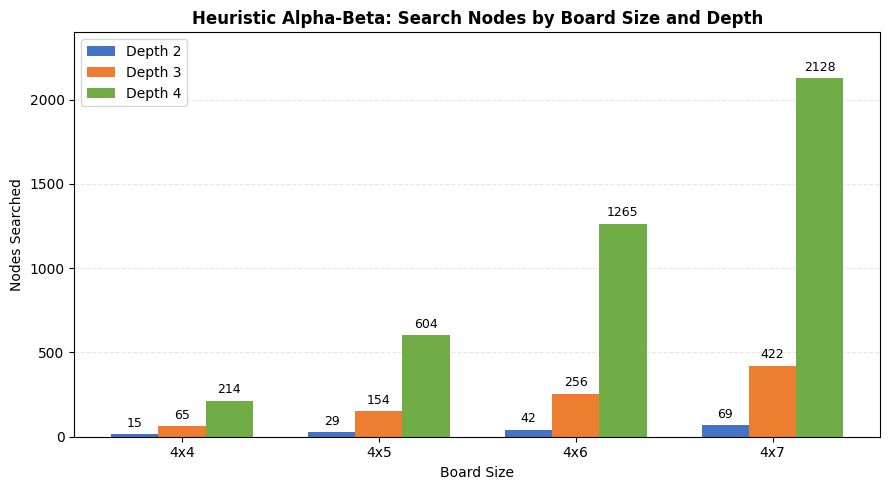

In [105]:
# Figure 3.4 - Heuristic Alpha-Beta Search Nodes

import matplotlib.pyplot as plt
import numpy as np

board_sizes = ["4x4", "4x5", "4x6", "4x7"]

depth_2 = [15, 29, 42, 69]
depth_3 = [65, 154, 256, 422]
depth_4 = [214, 604, 1265, 2128]

x = np.arange(len(board_sizes))
width = 0.24

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width, depth_2, width,
               label="Depth 2", color="#4472C4")

bars2 = ax.bar(x, depth_3, width,
               label="Depth 3", color="#ED7D31")

bars3 = ax.bar(x + width, depth_4, width,
               label="Depth 4", color="#70AD47")

for bars in [bars1, bars2, bars3]:
    ax.bar_label(bars, padding=3, fontsize=9)

ax.set_title(
    "Heuristic Alpha-Beta: Search Nodes by Board Size and Depth",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Board Size")
ax.set_ylabel("Nodes Searched")
ax.set_xticks(x)
ax.set_xticklabels(board_sizes)
ax.legend()

ax.set_ylim(0, 2400)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Nhận xét – Execution Time with Depth Cutoff

Cả 12 cấu hình đều hoàn thành tìm kiếm. Trên bàn 4×7, khi tăng độ sâu từ 2 lên 4, số nút tăng từ 69 lên 2.128, cho thấy chi phí tính toán tăng đáng kể theo độ sâu.

### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [106]:
# Task 4 - Playtime: Two Heuristic Alpha-Beta Agents

import numpy as np
import time

# Agent MIN uses a different heuristic function
def heuristic_eval_center(board, connect=4):
    board = np.asarray(board)
    rows, cols = board.shape

    final_value = utility(board, player=1, connect=connect)
    if final_value is not None:
        return final_value * 100000

    # Alternative weights
    weights = {1: 2, 2: 8, 3: 40}
    score = 0

    directions = [(0, 1), (1, 0), (1, 1), (1, -1)]

    for r in range(rows):
        for c in range(cols):
            for dr, dc in directions:
                end_r = r + (connect - 1) * dr
                end_c = c + (connect - 1) * dc

                if not (0 <= end_r < rows and 0 <= end_c < cols):
                    continue

                window = [
                    int(board[r + k * dr, c + k * dc])
                    for k in range(connect)
                ]

                x = window.count(1)
                o = window.count(-1)

                if x > 0 and o == 0:
                    score += weights.get(x, 0)
                elif o > 0 and x == 0:
                    score -= weights.get(o, 0)

    # Prefer occupying central columns
    for c in range(cols):
        center_bonus = max(0, cols - 2 * abs(c - (cols - 1) / 2))
        score += center_bonus * np.sum(board[:, c])

    return float(score)


# Alpha-Beta supporting different evaluation functions
def custom_heuristic_alpha_beta(
    board, player, max_depth, eval_fn, max_nodes=30000
):
    nodes = 0

    def search(state, turn, depth, alpha, beta, path):
        nonlocal nodes
        nodes += 1

        if nodes > max_nodes:
            raise RuntimeError("Node limit reached")

        final = utility(state, turn)
        if final is not None:
            return final * 100000

        key = (state.tobytes(), turn)

        if key in path:
            return 0

        if depth == 0:
            return eval_fn(state)

        next_path = path | {key}

        if turn == 1:
            best = -float("inf")

            for action in actions(state, turn):
                child = result(state, action, turn)
                value = search(
                    child, -turn, depth - 1,
                    alpha, beta, next_path
                )
                best = max(best, value)
                alpha = max(alpha, best)

                if alpha >= beta:
                    break
        else:
            best = float("inf")

            for action in actions(state, turn):
                child = result(state, action, turn)
                value = search(
                    child, -turn, depth - 1,
                    alpha, beta, next_path
                )
                best = min(best, value)
                beta = min(beta, best)

                if alpha >= beta:
                    break

        return best

    if max_depth < 1:
        raise ValueError("max_depth must be at least 1")

    if terminal(board, player):
        return None, eval_fn(board), 0

    best_action = None
    best_value = -float("inf") if player == 1 else float("inf")
    alpha, beta = -float("inf"), float("inf")

    for action in actions(board, player):
        child = result(board, action, player)
        value = search(
            child, -player, max_depth - 1,
            alpha, beta, {(board.tobytes(), player)}
        )

        if ((player == 1 and value > best_value) or
            (player == -1 and value < best_value)):
            best_value = value
            best_action = action

        if player == 1:
            alpha = max(alpha, best_value)
        else:
            beta = min(beta, best_value)

    return best_action, best_value, nodes


# Play one deterministic game
board = empty_board((4, 7))
turn = 1
max_turns = 80
move_log = []
status = "Unfinished"
start = time.perf_counter()

print("=== HEURISTIC AGENT VS HEURISTIC AGENT ===")
print("MAX: Depth 3, original heuristic")
print("MIN: Depth 2, center-weighted heuristic")

for move_number in range(1, max_turns + 1):

    if terminal(board, turn):
        status = "Terminal"
        break

    if turn == 1:
        depth = 3
        evaluation = heuristic_eval
    else:
        depth = 2
        evaluation = heuristic_eval_center

    try:
        action, value, nodes = custom_heuristic_alpha_beta(
            board, turn, depth, evaluation
        )
    except RuntimeError:
        status = "Search limit reached"
        break

    if action is None:
        status = "No legal action"
        break

    board = result(board, action, turn)

    move_log.append((move_number, turn, action, value, nodes))

    print(
        f"Move {move_number:02d} | "
        f"Player {turn:+d} | "
        f"{action} | Score: {value:.1f} | "
        f"Nodes: {nodes}"
    )

    turn = -turn

else:
    status = "Turn limit reached"

elapsed = time.perf_counter() - start
winners = check_winner(board)

print("\n=== FINAL RESULT ===")
print("Final board:")
print(board)

if winners == {1}:
    print("Winner: MAX (Depth 3)")
elif winners == {-1}:
    print("Winner: MIN (Depth 2)")
elif winners == {1, -1}:
    print("Result: Simultaneous winners (treated as draw)")
elif terminal(board, turn):
    print("Result: Draw")
else:
    print("Result: Unfinished")

print("Status:", status)
print("Total moves:", len(move_log))
print(f"Total time: {elapsed:.3f} seconds")


=== HEURISTIC AGENT VS HEURISTIC AGENT ===
MAX: Depth 3, original heuristic
MIN: Depth 2, center-weighted heuristic
Move 01 | Player +1 | ('drop', 3) | Score: 17.0 | Nodes: 422
Move 02 | Player -1 | ('drop', 3) | Score: 27.0 | Nodes: 90
Move 03 | Player +1 | ('drop', 2) | Score: 15.0 | Nodes: 613
Move 04 | Player -1 | ('move', 3, 0) | Score: 24.0 | Nodes: 111
Move 05 | Player +1 | ('drop', 3) | Score: 27.0 | Nodes: 706
Move 06 | Player -1 | ('move', 2, 6) | Score: 38.0 | Nodes: 168
Move 07 | Player +1 | ('drop', 2) | Score: 42.0 | Nodes: 1240
Move 08 | Player -1 | ('drop', 1) | Score: 57.0 | Nodes: 164
Move 09 | Player +1 | ('drop', 1) | Score: 106.0 | Nodes: 1361
Move 10 | Player -1 | ('drop', 2) | Score: 59.0 | Nodes: 101
Move 11 | Player +1 | ('drop', 4) | Score: 115.0 | Nodes: 3743
Move 12 | Player -1 | ('move', 4, 0) | Score: 66.0 | Nodes: 238
Move 13 | Player +1 | ('move', 1, 6) | Score: 134.0 | Nodes: 3437
Move 14 | Player -1 | ('move', 2, 6) | Score: 78.0 | Nodes: 293
Move 15 |

=== FINAL BOARD: HEURISTIC VS HEURISTIC ===
Winner: {1}


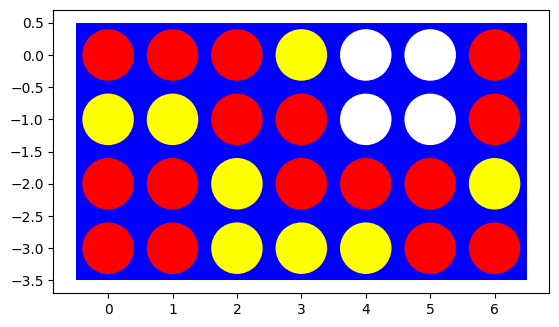

In [107]:
# Figure 3.5 - Final Board: Heuristic vs Heuristic

print("=== FINAL BOARD: HEURISTIC VS HEURISTIC ===")
print("Winner:", check_winner(board))

visualize(board)
plt.show()

### Nhận xét – Heuristic Alpha-Beta vs Heuristic Alpha-Beta

Agent MAX (Depth 3) thắng Agent MIN (Depth 2) sau 33 lượt trên bàn 4×7, với thời gian 2,035 giây. Một ván đấu chưa đủ để kết luận tác tử nào mạnh hơn về tổng thể.

## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [108]:
# Graduate Advanced Task - Pure Monte Carlo Search

import numpy as np
import time


def monte_carlo_rollout(
    board,
    player,
    root_player,
    max_turns=100
):
    """
    Play one random simulation.

    Returns:
        1.0 -> root player wins
        0.5 -> draw
        0.0 -> root player loses
        None -> simulation did not finish
    """

    state = np.asarray(board).copy()
    turn = player

    visited = set()

    for _ in range(max_turns):

        # Check terminal state
        if terminal(state, turn):
            winners = check_winner(state)

            if len(winners) == 0 or len(winners) == 2:
                return 0.5

            winner = next(iter(winners))

            return 1.0 if winner == root_player else 0.0

        # Detect repeated states
        key = (state.tobytes(), turn)

        if key in visited:
            return None

        visited.add(key)

        legal = actions(state, turn)

        if not legal:
            return 0.5

        # Random action
        action = legal[np.random.randint(len(legal))]

        state = result(state, action, turn)
        turn = -turn

    # Move limit reached
    return None


def pure_monte_carlo_search(
    board,
    player=1,
    simulations=50,
    max_turns=100
):
    """
    Evaluate each legal action using random simulations.

    Returns:
        best_action, best_score, results, elapsed
    """

    if simulations < 1:
        raise ValueError("simulations must be >= 1")

    start = time.perf_counter()
    legal = actions(board, player)

    
    if terminal(board, player) or not legal:
        return None, None, [], time.perf_counter() - start

    # Tactical check: prefer an immediate winning move
    for action in legal:
        next_board = result(board, action, player)
        winners = check_winner(next_board)

        if winners == {player}:
            elapsed = time.perf_counter() - start

            return (
                action,
                1.0,
                [{
                    "action": action,
                    "score": 1.0,
                    "completed": 0,
                    "unfinished": 0
                }],
                elapsed
            )

    results = []

    for action in legal:

        next_board = result(board, action, player)

        scores = []
        unfinished = 0

        for _ in range(simulations):

            score = monte_carlo_rollout(
                next_board,
                player=-player,
                root_player=player,
                max_turns=max_turns
            )

            if score is None:
                unfinished += 1
            else:
                scores.append(score)

        # Estimate from completed simulations only
        avg_score = (
            float(np.mean(scores))
            if scores else None
        )

        results.append({
            "action": action,
            "score": avg_score,
            "completed": len(scores),
            "unfinished": unfinished
        })

    # Prefer estimated score, then sample count
    valid_results = [
        item for item in results
        if item["score"] is not None
    ]

    if valid_results:
        best = max(
            valid_results,
            key=lambda x: (x["score"], x["completed"])
        )

        best_action = best["action"]
        best_score = best["score"]
    else:
        best_action = None
        best_score = None

    elapsed = time.perf_counter() - start

    return best_action, best_score, results, elapsed


def pure_monte_carlo_player(board, player=1):
    action, score, results, elapsed = (
        pure_monte_carlo_search(
            board,
            player=player,
            simulations=50
        )
    )

    return action


print("=== PURE MONTE CARLO SEARCH READY ===")


=== PURE MONTE CARLO SEARCH READY ===


In [109]:
# Graduate Advanced Task - Monte Carlo Tests

import numpy as np

np.random.seed(1111)

# Reuse manually created boards from Task 4
mc_test_cases = [
    ("MAX immediate win", test_boards[0][1], 1),
    ("MIN immediate win", test_boards[1][1], -1),
    ("MAX must block MIN", test_boards[3][1], 1)
]

print("=== PURE MONTE CARLO SEARCH TESTS ===")

for name, board, player in mc_test_cases:

    print(f"\n--- {name} ---")

    best_action, best_score, results, elapsed = (
        pure_monte_carlo_search(
            board,
            player=player,
            simulations=50,
            max_turns=100
        )
    )

    print("Best action:", best_action)
    print("Estimated win score:", best_score)
    print(f"Execution time: {elapsed:.4f} seconds")

    print("\nAction evaluations:")

    for item in results:
        print(
            f"{item['action']} | "
            f"Score: {item['score']} | "
            f"Completed: {item['completed']} | "
            f"Unfinished: {item['unfinished']}"
        )

    if best_action is not None:
        next_board = result(board, best_action, player)

        print("\nWinner after selected move:",
              check_winner(next_board))

print("\n=== TESTS COMPLETED ===")


=== PURE MONTE CARLO SEARCH TESTS ===

--- MAX immediate win ---
Best action: ('drop', 3)
Estimated win score: 1.0
Execution time: 0.0001 seconds

Action evaluations:
('drop', 3) | Score: 1.0 | Completed: 0 | Unfinished: 0

Winner after selected move: {1}

--- MIN immediate win ---
Best action: ('drop', 3)
Estimated win score: 1.0
Execution time: 0.0000 seconds

Action evaluations:
('drop', 3) | Score: 1.0 | Completed: 0 | Unfinished: 0

Winner after selected move: {-1}

--- MAX must block MIN ---
Best action: ('drop', 2)
Estimated win score: 0.0
Execution time: 0.1068 seconds

Action evaluations:
('drop', 0) | Score: 0.0 | Completed: 47 | Unfinished: 3
('drop', 1) | Score: 0.0 | Completed: 48 | Unfinished: 2
('drop', 2) | Score: 0.0 | Completed: 50 | Unfinished: 0
('drop', 3) | Score: 0.0 | Completed: 47 | Unfinished: 3
('move', 0, 0) | Score: 0.0 | Completed: 50 | Unfinished: 0
('move', 0, 1) | Score: 0.0 | Completed: 50 | Unfinished: 0
('move', 0, 2) | Score: 0.0 | Completed: 49 | U

### Nhận xét – Pure Monte Carlo Search

Monte Carlo Search mô phỏng ngẫu nhiên để ước lượng chất lượng nước đi. Sau khi bổ sung kiểm tra thắng tức thời, tác tử nhận diện đúng hai tình huống thắng, nhưng khả năng phòng thủ vẫn chưa ổn định.

### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [110]:
# Graduate Advanced Task - Best First Move

import numpy as np

np.random.seed(1111)

board = empty_board((6, 7))

print("=== BEST FIRST MOVE: MEAN CONNECT 4 ===")
print("Board size: 6 x 7")
print("Player: MAX (+1)")

best_action, best_score, results, elapsed = (
    pure_monte_carlo_search(
        board,
        player=1,
        simulations=200,
        max_turns=100
    )
)

print("\nAction evaluations:")

for item in results:
    print(
        f"{item['action']} | "
        f"Score: {item['score']} | "
        f"Completed: {item['completed']} | "
        f"Unfinished: {item['unfinished']}"
    )

print("\n=== FINAL RESULT ===")
print("Best first move:", best_action)
print("Estimated score:", best_score)
print(f"Execution time: {elapsed:.4f} seconds")

if best_action is not None:
    print("\nBoard after selected move:")
    print(result(board, best_action, 1))


=== BEST FIRST MOVE: MEAN CONNECT 4 ===
Board size: 6 x 7
Player: MAX (+1)

Action evaluations:
('drop', 0) | Score: 0.7978142076502732 | Completed: 183 | Unfinished: 17
('drop', 1) | Score: 0.7594594594594595 | Completed: 185 | Unfinished: 15
('drop', 2) | Score: 0.7960893854748603 | Completed: 179 | Unfinished: 21
('drop', 3) | Score: 0.776595744680851 | Completed: 188 | Unfinished: 12
('drop', 4) | Score: 0.7786885245901639 | Completed: 183 | Unfinished: 17
('drop', 5) | Score: 0.767379679144385 | Completed: 187 | Unfinished: 13
('drop', 6) | Score: 0.6693548387096774 | Completed: 186 | Unfinished: 14

=== FINAL RESULT ===
Best first move: ('drop', 0)
Estimated score: 0.7978142076502732
Execution time: 1.1033 seconds

Board after selected move:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0]]


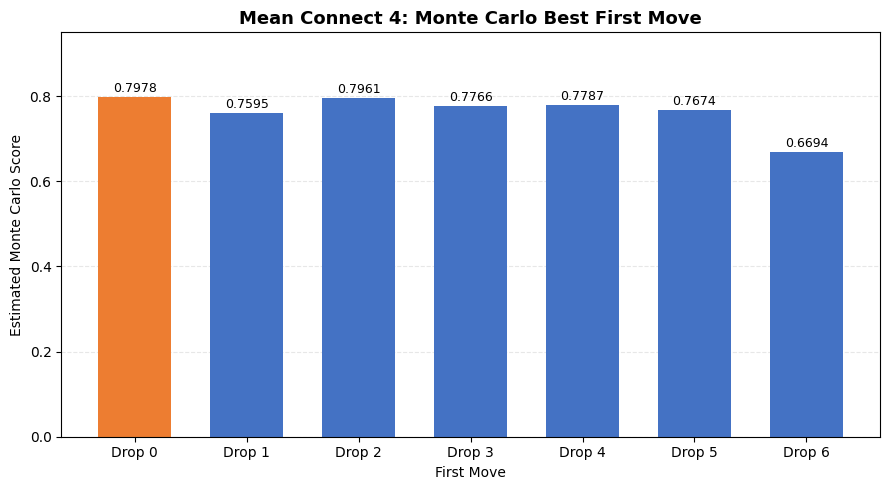

In [111]:
# Figure 3.6 - Monte Carlo Best First Move

import matplotlib.pyplot as plt

# Results from the latest notebook
actions_labels = [f"Drop {i}" for i in range(7)]
scores = [0.7978, 0.7595, 0.7961, 0.7766,
          0.7787, 0.7674, 0.6694]

colors = [
    "#4472C4" if i != 0 else "#ED7D31"
    for i in range(7)
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    actions_labels,
    scores,
    color=colors,
    width=0.65
)

for bar, score in zip(bars, scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.012,
        f"{score:.4f}",
        ha="center",
        fontsize=9
    )

ax.set_title(
    "Mean Connect 4: Monte Carlo Best First Move",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("First Move")
ax.set_ylabel("Estimated Monte Carlo Score")
ax.set_ylim(0, 0.95)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Nhận xét – Best First Move

Trên bàn 6×7, Monte Carlo chọn `('drop', 0)` với điểm ước lượng cao nhất là 0,7978 sau 200 mô phỏng mỗi nước. Đây là kết quả thực nghiệm, chưa chứng minh nước đi này tối ưu.